Time Series Prediction Lab - RNN Comparison
Generating synthetic time series...


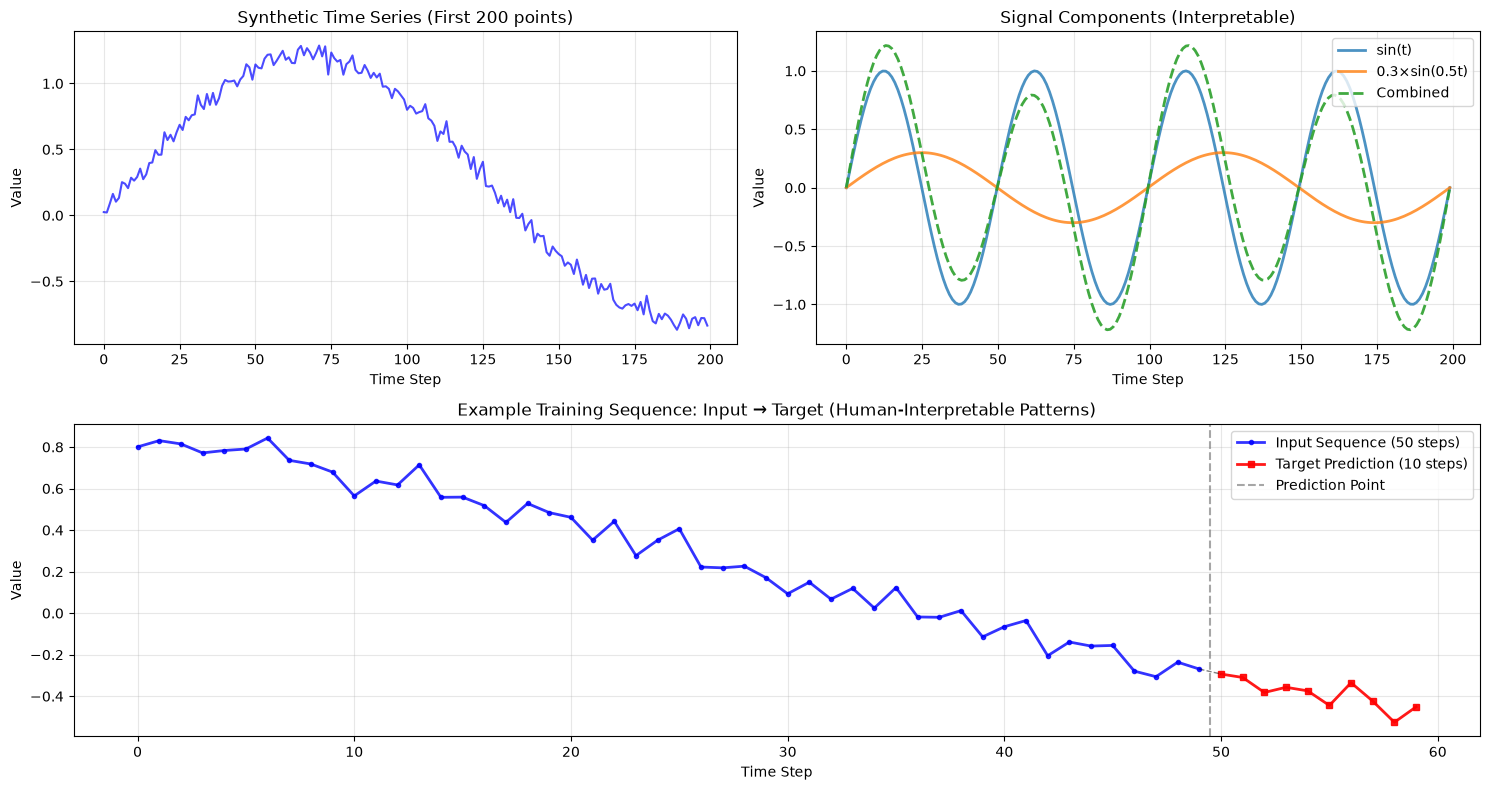

Creating sequences...
Input shape: (941, 50), Output shape: (941, 10)
Training samples: 752, Test samples: 189
Model classes defined - complete the implementations!

Training Models

Training Vanilla RNN...
------------------------------
Number of parameters: 1450
Epoch [10/50], Loss: 0.0248
Epoch [20/50], Loss: 0.0218
Epoch [30/50], Loss: 0.0194
Epoch [40/50], Loss: 0.0172
Epoch [50/50], Loss: 0.0159
Training completed in 5.97 seconds
All predictions  0 (32, 10)
All predictions  1 (32, 10)
All predictions  2 (32, 10)
All predictions  3 (32, 10)
All predictions  4 (32, 10)
All predictions  5 (29, 10)
All actuals  0 (32, 10)
All actuals  1 (32, 10)
All actuals  2 (32, 10)
All actuals  3 (32, 10)
All actuals  4 (32, 10)
All actuals  5 (29, 10)
All inputs     0 (32, 50)
All inputs     1 (32, 50)
All inputs     2 (32, 50)
All inputs     3 (32, 50)
All inputs     4 (32, 50)
All inputs     5 (29, 50)

Training LSTM...
------------------------------
Number of parameters: 4810
Epoch [10/50], L

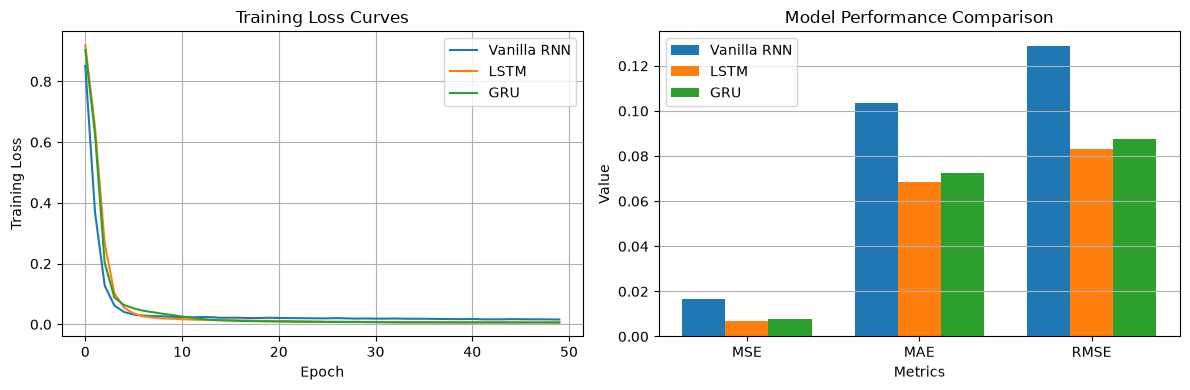


Sample Predictions Visualization

Vanilla RNN Predictions:


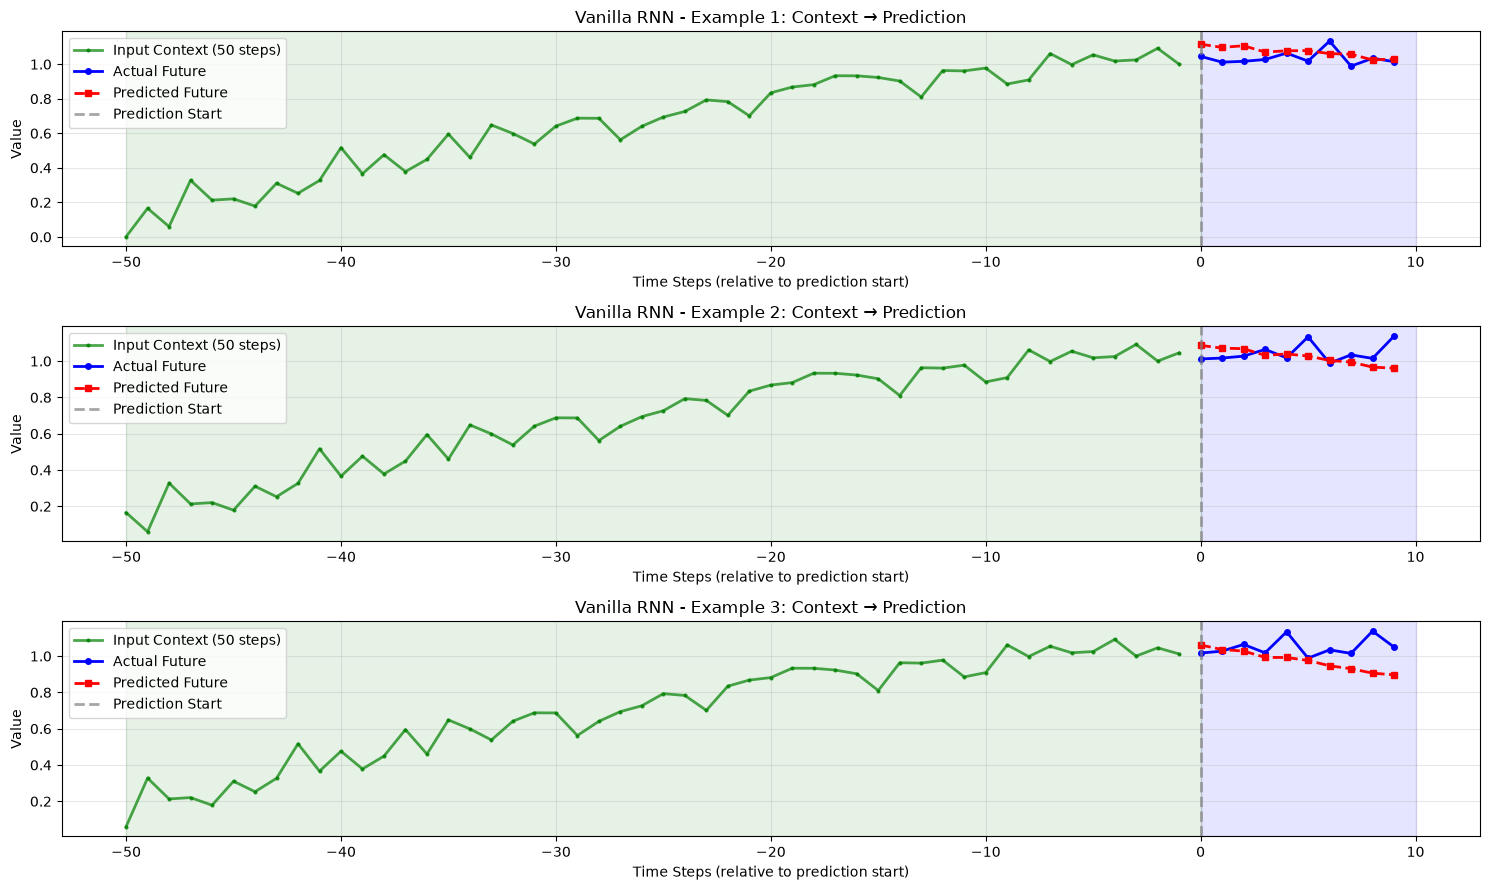


LSTM Predictions:


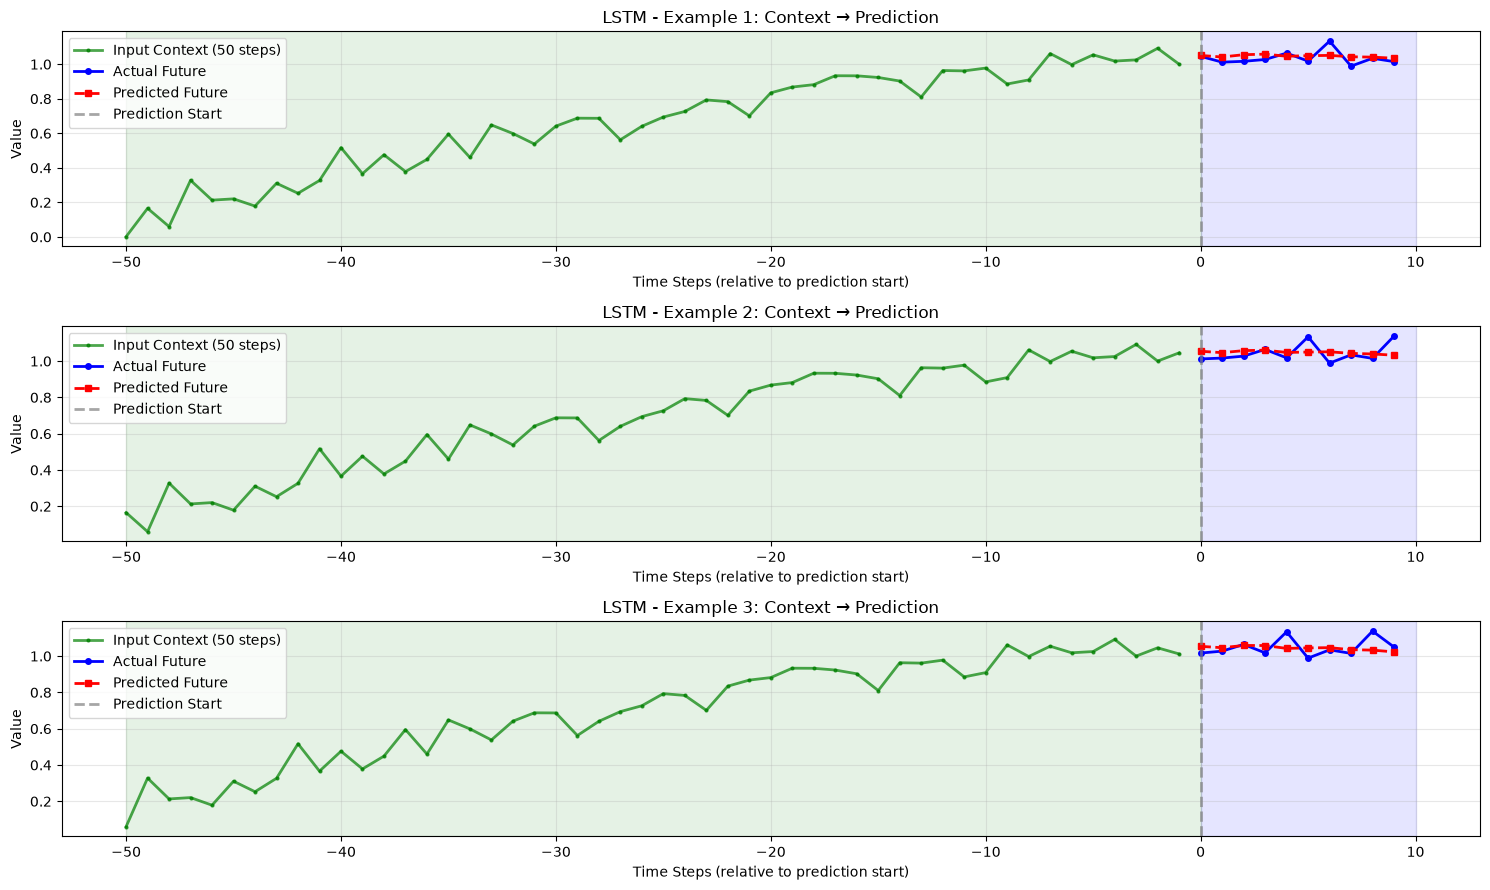


GRU Predictions:


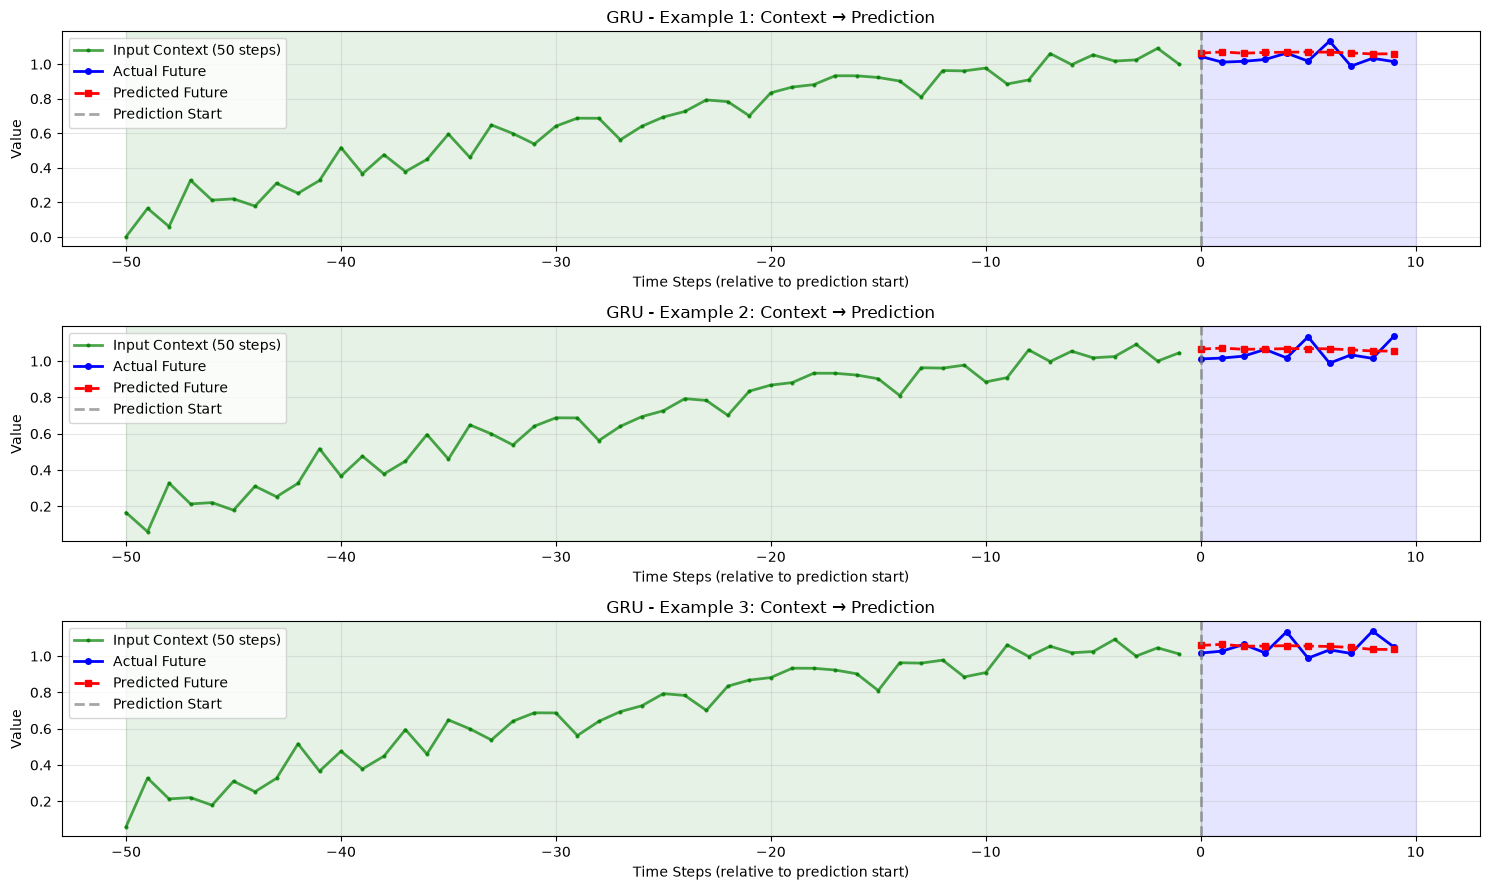


Student Exercise Instructions

Complete the following TODO items to make this lab work:

1. MODEL IMPLEMENTATIONS (Part 2):
   - VanillaRNN: Define self.rnn and self.fc layers, implement forward()
   - LSTMNet: Define self.lstm and self.fc layers, implement forward()  
   - GRUNet: Define self.gru and self.fc layers, implement forward()

2. TRAINING FUNCTION (Part 3):
   - Define criterion = nn.MSELoss()
   - Define optimizer = torch.optim.Adam(model.parameters(), lr=lr)
   - Implement training loop: zero_grad(), forward(), loss(), backward(), step()

3. EVALUATION FUNCTION (Part 4):
   - Get predictions from model
   - Calculate loss
   - Store predictions, actuals, and inputs in lists

4. MAIN EXPERIMENT (Part 6):
   - Initialize the three models in the models dictionary
   - Call train_model() for each model
   - Call evaluate_model() for each model

When complete, you should see:
- Training progress for all three models
- Performance comparison table
- Training curve plots
- Predi

In [1]:
# Time Series Prediction with RNNs - Student Lab Template
# ========================================================
# TODO: Fill in the missing implementations marked with # YOUR CODE HERE
# When I was done, I marked part with DONE.

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time
import pandas as pd

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

print("Time Series Prediction Lab - RNN Comparison")
print("=" * 50)

# ================================
# Part 1: Data Generation & Preparation (PROVIDED)
# ================================

def create_timeseries(length=1000, noise_level=0.05, pattern_type='simple'):
    """Generate synthetic time series with human-interpretable patterns"""
    t = np.linspace(0, 8*np.pi, length)  # More cycles for pattern recognition
    
    if pattern_type == 'simple':
        # Simple sine wave - most interpretable
        signal = np.sin(t) + 0.3*np.sin(0.5*t)  # Two clear components
    elif pattern_type == 'seasonal':
        # Seasonal pattern with trend
        signal = (np.sin(t) + 0.5*np.sin(t/4) +  # Main + seasonal cycle
                 0.02*t + np.sin(t/8))  # Trend + long-term cycle
    elif pattern_type == 'complex':
        # Original complex version
        signal = (np.sin(t) + 0.5*np.sin(2*t) + 0.3*np.sin(5*t) + 
                 0.02*t)
    
    # Add noise
    signal += noise_level * np.random.randn(length)
    return signal

def create_sequences(data, seq_length=50, pred_length=10):
    """Create input-output pairs for time series prediction"""
    X, y = [], []
    for i in range(len(data) - seq_length - pred_length + 1):
        X.append(data[i:(i + seq_length)])
        y.append(data[(i + seq_length):(i + seq_length + pred_length)])
    return np.array(X), np.array(y)

# Generate and prepare data (PROVIDED)
print("Generating synthetic time series...")
data = create_timeseries(1000, noise_level=0.05, pattern_type='simple')

# Visualization code (PROVIDED)
plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.plot(data[:200], 'b-', alpha=0.7)
plt.title('Synthetic Time Series (First 200 points)')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
t = np.linspace(0, 8*np.pi, 200)
component1 = np.sin(t[:200])
component2 = 0.3*np.sin(0.5*t[:200])
plt.plot(component1, label='sin(t)', alpha=0.8, linewidth=2)
plt.plot(component2, label='0.3×sin(0.5t)', alpha=0.8, linewidth=2)
plt.plot(component1 + component2, label='Combined', alpha=0.9, linewidth=2, linestyle='--')
plt.title('Signal Components (Interpretable)')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
example_idx = 100
seq_length = 50
pred_length = 10
input_seq = data[example_idx:example_idx + seq_length]
target_seq = data[example_idx + seq_length:example_idx + seq_length + pred_length]
input_times = range(seq_length)
target_times = range(seq_length, seq_length + pred_length)

plt.plot(input_times, input_seq, 'b-o', linewidth=2, markersize=3, 
         label=f'Input Sequence (50 steps)', alpha=0.8)
plt.plot(target_times, target_seq, 'r-s', linewidth=2, markersize=4, 
         label=f'Target Prediction (10 steps)', alpha=0.9)
plt.plot([input_times[-1], target_times[0]], [input_seq[-1], target_seq[0]], 
         'k--', alpha=0.5, linewidth=1)
plt.axvline(x=seq_length-0.5, color='gray', linestyle='--', alpha=0.7, 
            label='Prediction Point')
plt.title(f'Example Training Sequence: Input → Target (Human-Interpretable Patterns)')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Data preparation (PROVIDED)
print("Creating sequences...")
X, y = create_sequences(data, seq_length=50, pred_length=10)
print(f"Input shape: {X.shape}, Output shape: {y.shape}")

mean_val = np.mean(X)
std_val = np.std(X)
X = (X - mean_val) / std_val
y = (y - mean_val) / std_val

split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

X_train = torch.FloatTensor(X_train).unsqueeze(-1)
X_test = torch.FloatTensor(X_test).unsqueeze(-1)
y_train = torch.FloatTensor(y_train)
y_test = torch.FloatTensor(y_test)

batch_size = 32
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training samples: {len(X_train)}, Test samples: {len(X_test)}")

# ================================
# Part 2: Model Implementations - STUDENT EXERCISE
# ================================

class VanillaRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=10):
        super(VanillaRNN, self).__init__()
        self.hidden_size = hidden_size
        self.input_size = input_size
        
        # DONE: Define the RNN layer
        # HINT: Use nn.RNN(input_size, hidden_size, batch_first=True)
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True) 

        # DONE: Define the fully connected output layer
        # HINT: Use nn.Linear to map from hidden_size to output_size
        # YOUR CODE HERE
        self.fc = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # DONE: Implement the forward pass
        # HINT: 
        # 1. Pass x through the RNN layer
        out, hidden = self.rnn(x)    
        
        # 2. Use the last time step output for prediction
        out = out[:,-1,:]
        
        # 3. Pass through the fully connected layer
        # YOUR CODE HERE
        out = self.fc(out)

        return out
    
class LSTMNet(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=10):
        super(LSTMNet, self).__init__()
        self.hidden_size = hidden_size
        
        # DONE: Define the LSTM layer
        # HINT: Use nn.LSTM(input_size, hidden_size, batch_first=True)
        # YOUR CODE HERE
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)

        # DONE: Define the fully connected output layer
        # YOUR CODE HERE
        self.fully_connect = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # DONE: Implement the forward pass
        # HINT: LSTM returns (output, (hidden, cell)) tuple
        # YOUR CODE HERE
        
        # this way all the data does not assign only to out
        out, (hidden, cell) =  self.lstm(x)

        out = self.fully_connect(out[:,-1,:]) 
        
        # and we return only out.
        return out

class GRUNet(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=10):
        super(GRUNet, self).__init__()
        self.hidden_size = hidden_size
        
        # DONE: Define the GRU layer
        # HINT: Use nn.GRU(input_size, hidden_size, batch_first=True)
        # YOUR CODE HERE

        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        
        # DONE: Define the fully connected output layer
        # YOUR CODE HERE
        self.fully_connect = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # DONE: Implement the forward pass
        # HINT: GRU returns (output, hidden) tuple
        # YOUR CODE HERE
        (out, hidden) = self.gru(x)
        
        out = self.fully_connect(out[:,-1,:])
        
        return out

print("Model classes defined - complete the implementations!")

# ================================
# Part 3: Training Function - STUDENT EXERCISE
# ================================

def train_model(model, train_loader, num_epochs=50, lr=0.001):
    """Train a model and return training losses"""
    
    # DONE: Define loss function and optimizer
    # HINT: Use nn.MSELoss() and torch.optim.Adam()
    # YOUR CODE HERE
    
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    losses = []
    start_time = time.time()
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        model.train()
        
        for batch_x, batch_y in train_loader:

            # YOUR CODE HERE

            # DONE: Implement training step
            # 1. Zero gradients
            optimizer.zero_grad()
            
            # 2. Forward pass
            outputs = model(batch_x)

            
            # 3. Calculate loss
            loss = criterion(outputs, batch_y)

            # 4. Backward pass
            loss.backward()
            
            # 5. Optimizer step
            optimizer.step()

            # because next we use it to calculate avg_loss
            epoch_loss += loss.item()
            
        
        avg_loss = epoch_loss / len(train_loader)
        losses.append(avg_loss)
        
        if (epoch + 1) % 10 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}')
    
    training_time = time.time() - start_time
    print(f'Training completed in {training_time:.2f} seconds')
    
    return losses, training_time

# ================================
# Part 4: Evaluation Function - STUDENT EXERCISE
# ================================

def evaluate_model(model, test_loader):
    """Evaluate model performance on test set"""
    model.eval()
    total_loss = 0
    all_predictions = []
    all_actuals = []
    all_inputs = []
    
    criterion = nn.MSELoss()
    
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            # DONE: Implement evaluation step
            # HINT:
            
            # YOUR CODE HERE
            # 1. Get model predictions
            outputs = model(batch_x)
            
            # 2. Calculate loss
            correct = criterion(outputs,batch_y)
            total_loss += correct.item()

            # 3. Store predictions, actuals, and inputs for analysis
            # numpy because we later do all_predictions = np.array().
            all_predictions.append(outputs.numpy())
            all_actuals.append(batch_y.numpy())
            all_inputs.append(batch_x.squeeze(-1).numpy())


    ''' We can see, that last batches have 29 samples, while others have 32. It happens, because our initial data has 189 samples.
        np.array() can not add these all batches because they differ in size. It throws an error:
     
        ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (6,) + inhomogeneous part.
        
        I googled the error and on forums people said it is because the shapes are different. I checked, and sizes were different, but I did not know how to fix it, so I asked Claude for help.
        It recommended to use concatenate. I then googled what concatenate would do in this case and then I tried it.
        np.concatenate() adds all these batches into one big batch of (189, 10). axis = 0 is used so it makes one list with all batches
         
    '''
    for i, j in enumerate(all_predictions):
        print("All predictions ", i, j.shape)
        
    for i, j in enumerate(all_actuals):
        print("All actuals ", i, j.shape)
        
    for i, j in enumerate(all_inputs):
        print("All inputs    ", i, j.shape)
            
        
    all_predictions = np.concatenate(all_predictions, axis= 0)
    all_actuals = np.concatenate(all_actuals, axis = 0)
    all_inputs = np.concatenate(all_inputs, axis = 0)
    
    # Calculate metrics (PROVIDED)
    mse = total_loss / len(test_loader)
    mae = mean_absolute_error(all_actuals.flatten(), all_predictions.flatten())
    rmse = np.sqrt(mean_squared_error(all_actuals.flatten(), all_predictions.flatten()))
    
    return {
        'mse': mse,
        'mae': mae,
        'rmse': rmse,
        'predictions': all_predictions,
        'actuals': all_actuals,
        'inputs': all_inputs
    }

# ================================
# Part 5: Visualization Function (PROVIDED)
# ================================

def plot_predictions(model_name, predictions, actuals, input_sequences, num_examples=3):
    """Plot input context + actual vs predicted sequences"""
    plt.figure(figsize=(15, 3*num_examples))
    
    for i in range(num_examples):
        plt.subplot(num_examples, 1, i+1)
        
        input_times = range(-50, 0)
        plt.plot(input_times, input_sequences[i], 'g-', linewidth=2, alpha=0.7,
                label='Input Context (50 steps)', marker='o', markersize=2)
        
        pred_times = range(0, 10)
        plt.plot(pred_times, actuals[i], 'b-o', label='Actual Future', linewidth=2, markersize=4)
        plt.plot(pred_times, predictions[i], 'r--s', label='Predicted Future', linewidth=2, markersize=4)
        
        plt.axvline(x=0, color='gray', linestyle='--', alpha=0.7, linewidth=2, 
                   label='Prediction Start')
        
        plt.xlabel('Time Steps (relative to prediction start)')
        plt.ylabel('Value')
        plt.title(f'{model_name} - Example {i+1}: Context → Prediction')
        plt.legend(loc='upper left')
        plt.grid(True, alpha=0.3)
        
        plt.axvspan(-50, 0, alpha=0.1, color='green', label='_nolegend_')
        plt.axvspan(0, 10, alpha=0.1, color='blue', label='_nolegend_')
    
    plt.tight_layout()
    plt.show()

# ================================
# Part 6: Main Experiment - STUDENT EXERCISE
# ================================

print("\n" + "=" * 50)
print("Training Models")
print("=" * 50)

# DONE: Initialize the three models
# YOUR CODE HERE
models = {
    'Vanilla RNN': VanillaRNN(),  # VanillaRNN()
    'LSTM': LSTMNet(),         # LSTMNet()
    'GRU': GRUNet()          # GRUNet()
}

results = {}
training_histories = {}

# DONE: Train each model and evaluate
for name, model in models.items():
    if model is None:
        print(f"Skipping {name} - not implemented yet")
        continue
        
    print(f"\nTraining {name}...")
    print("-" * 30)
    
    num_params = sum(p.numel() for p in model.parameters())
    print(f"Number of parameters: {num_params}")
    
    # DONE: Train the model
    # YOUR CODE HERE
    losses, training_time = train_model(model,train_loader) # Replace with actual training call
    
    if losses is not None:
        training_histories[name] = losses
        
        # DONE: Evaluate the model
        # YOUR CODE HERE
        eval_results = evaluate_model(model, test_loader)# Replace with actual evaluation call
        
        if eval_results is not None:
            eval_results['training_time'] = training_time
            eval_results['num_params'] = num_params
            results[name] = eval_results

# ================================
# Part 7: Results Analysis (PROVIDED - will work once models are implemented)
# ================================

if results:
    print("\n" + "=" * 50)
    print("Results Comparison")
    print("=" * 50)
    
    results_df = pd.DataFrame({
        name: {
            'MSE': results[name]['mse'],
            'MAE': results[name]['mae'], 
            'RMSE': results[name]['rmse'],
            'Training Time (s)': results[name]['training_time'],
            'Parameters': results[name]['num_params']
        }
        for name in results.keys()
    }).T
    
    print(results_df.round(4))
    
    # Plot training curves and performance comparison
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    for name, losses in training_histories.items():
        plt.plot(losses, label=name)
    plt.xlabel('Epoch')
    plt.ylabel('Training Loss')
    plt.title('Training Loss Curves')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    metrics = ['MSE', 'MAE', 'RMSE']
    x = np.arange(len(metrics))
    width = 0.25
    
    for i, name in enumerate(results.keys()):
        values = [results[name]['mse'], results[name]['mae'], results[name]['rmse']]
        plt.bar(x + i*width, values, width, label=name)
    
    plt.xlabel('Metrics')
    plt.ylabel('Value')
    plt.title('Model Performance Comparison')
    plt.xticks(x + width, metrics)
    plt.legend()
    plt.grid(True, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    # Show prediction examples
    print("\n" + "=" * 50)
    print("Sample Predictions Visualization")
    print("=" * 50)
    
    for name in results.keys():
        print(f"\n{name} Predictions:")
        plot_predictions(name, 
                        results[name]['predictions'][:3], 
                        results[name]['actuals'][:3],
                        results[name]['inputs'][:3])

print("\n" + "=" * 50)
print("Student Exercise Instructions")
print("=" * 50)

print("""
Complete the following TODO items to make this lab work:

1. MODEL IMPLEMENTATIONS (Part 2):
   - VanillaRNN: Define self.rnn and self.fc layers, implement forward()
   - LSTMNet: Define self.lstm and self.fc layers, implement forward()  
   - GRUNet: Define self.gru and self.fc layers, implement forward()

2. TRAINING FUNCTION (Part 3):
   - Define criterion = nn.MSELoss()
   - Define optimizer = torch.optim.Adam(model.parameters(), lr=lr)
   - Implement training loop: zero_grad(), forward(), loss(), backward(), step()

3. EVALUATION FUNCTION (Part 4):
   - Get predictions from model
   - Calculate loss
   - Store predictions, actuals, and inputs in lists

4. MAIN EXPERIMENT (Part 6):
   - Initialize the three models in the models dictionary
   - Call train_model() for each model
   - Call evaluate_model() for each model

When complete, you should see:
- Training progress for all three models
- Performance comparison table
- Training curve plots
- Prediction visualizations with context

Good luck! 🚀
""")